# ЛЛ1 — оценка языковых моделей с открытыми весами

Исследование магистерского уровня. Здесь анализируются результаты собственного локального запуска: **360 ответов**, три модели, два режима и три начальных значения. Синтетические данные программных тестов в эти результаты не входят. Все пояснения — на русском; исходный эксперимент проведён на румынском.

In [1]:
from pathlib import Path
import json, sys, subprocess
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd()
RUN = ROOT / "results/final"
assert (ROOT / "data/questions.json").exists(), "Откройте блокнот из корня проекта"
sys.path.insert(0, str(ROOT / "src"))
from presentation import localize_records
pd.set_option("display.max_colwidth", 100)
def show_ru(records):
    display(pd.DataFrame(localize_records(records)))
print("Версия Python:", sys.version.split()[0])

Версия Python: 3.12.14


## Набор оценки

Эталоны заданы до запуска и не передавались моделям. Для чтения ниже показан вспомогательный русский перевод; входами моделей были румынские оригиналы из `data/questions.json`.

In [2]:
questions = json.loads((ROOT / "data/questions_ru.json").read_text(encoding="utf-8"))
show_ru([{k:q[k] for k in ["id", "category", "question", "reference_answer"]} for q in questions])

,Задание,Категория,Вопрос,Эталон
0,1,История,"В каком году произошло Объединение румынских княжеств, известное как Малое объединение?",1859
1,2,История,"Кто в 1859 году был избран господарем и Молдавии, и Валахии?",Александру Иоан Куза
2,3,История,В каком году 1 декабря в Алба-Юлии была принята резолюция об объединении Трансильвании с Румынией?,1918
3,4,История,Какова столица Республики Молдова?,Кишинёв (Chișinău)
4,5,История,"Как называется мирный договор, подписанный 28 июня 1919 года между Германией и союзными державами?",Версальский договор
5,6,История,Какой господарь Молдавии победил в битве при Васлуе в 1475 году?,Штефан Великий
6,7,Румынский язык,Какова форма множественного числа румынского существительного «cafea»?,cafele
7,8,Румынский язык,Выберите синоним румынского слова «rapid»: «iute» или «greoi».,iute
8,9,Румынский язык,Выберите правильную румынскую форму: «ar trebui să vii» или «ar trebui să vi».,ar trebui să vii
9,10,Румынский язык,Какой частью речи является «frumos» в румынском предложении «El cântă frumos»?,Наречие (adverb)


## Происхождение моделей

GGUF F16 из Docker AI. Каждый манифест и файл проверен SHA-256. Регистр тега важен: SmolLM2 `360m-f16` содержит Instruct.

In [3]:
specs = json.loads((ROOT / "data/models_oci.lock.json").read_text(encoding="utf-8"))
show_ru([{
    "model": m["model"], "manifest_digest": m["manifest_digest"],
    "GGUF_bytes": next(x["size"] for x in m["layers"] if x["file"] == "model.gguf")
} for m in specs])

,Модель,SHA-256 манифеста,"Размер GGUF, байт"
0,ai/qwen2.5:0.5B-F16,sha256:3e1aad67b4cc8e3dca660fe65f9f73edb598474284256ffdd9ba460b5b35ff26,994156864
1,ai/smollm2:360m-f16,sha256:5f2b4fbe1650dabbeb1d7c86750d20267614f1715e09ede366053a7f8984c2e7,725553760
2,ai/llama3.2:1B-F16,sha256:158533c5c78e4d5ddcc9251691e91fdab10031e4da28148c788f44c52af6dd5b,2479595360


## Повтор генерации — по необходимости

По умолчанию анализируются сохранённые реальные приложения. Флаг включается только для нового запуска, которому потребуется новая проверка, если ответы изменятся.

In [4]:
RUN_NEW_EXPERIMENT = False
if RUN_NEW_EXPERIMENT:
    subprocess.run([sys.executable, "src/pull_oci.py", "--locked", "data/models_oci.lock.json"], check=True)
    subprocess.run([sys.executable, "src/benchmark_gguf.py", "--run-id", "notebook-new-run"], check=True)
    print("Новый запуск сохранён отдельно; до итогового сравнения выполните проверку ответов.")
else:
    print("Анализ сохранённого собственного эксперимента без повторной генерации.")

Анализ сохранённого собственного эксперимента без повторной генерации.


## Полнота и целостность данных

In [5]:
import hashlib
manifest = json.loads((RUN / "manifest.json").read_text(encoding="utf-8"))
rows = json.loads((RUN / "scored.json").read_text(encoding="utf-8"))
assert manifest["status"] == "complete" and len(rows) == 360
assert len({(r["model"], r["id"], r["mode"], r["repetition"]) for r in rows}) == 360
assert all("audit" in r for r in rows)
assert manifest["dataset_sha256"] == hashlib.sha256((ROOT / "data/questions.json").read_bytes()).hexdigest()
assert all(r["answer_sha256"] == hashlib.sha256(r["answer"].encode()).hexdigest() for r in rows)
print("Все 360 ответов проверены; хеши набора и текстов совпадают.")
print("Процессор:", manifest["cpu"], "| версия реализации:", manifest["backend_version"])

Все 360 ответов проверены; хеши набора и текстов совпадают.
Процессор: AMD EPYC 9V74 80-Core Processor | версия реализации: 0.3.16


## Строгая оценка и проверка содержания

Правильный ответ может не содержать маркер. Нарушение формата рассматривается отдельно от фактической ошибки.

In [6]:
aggregate = pd.read_csv(RUN / "aggregate.csv")
show_ru(aggregate[["model", "mode", "factual_exact", "factual_content", "math_accuracy", "math_content", "steps_valid_rate", "complete_solution_rate"]].to_dict("records"))

,Модель,Режим,Факты: строгая точность,Факты: проверка содержания,Математика: строгая точность,Математика: проверка результата,Доля верных шагов,Доля полных решений
0,ai/llama3.2:1B-F16,Жадный,0.0,0.583333,0.375000,0.875000,0.625000,0.500000
1,ai/llama3.2:1B-F16,Выборка,0.0,0.611111,0.083333,0.750000,0.458333,0.416667
2,ai/qwen2.5:0.5B-F16,Жадный,0.0,0.083333,0.500000,0.875000,0.375000,0.375000
3,ai/qwen2.5:0.5B-F16,Выборка,0.0,0.111111,0.458333,0.791667,0.166667,0.166667
4,ai/smollm2:360m-f16,Жадный,0.0,0.166667,0.000000,0.625000,0.125000,0.125000
5,ai/smollm2:360m-f16,Выборка,0.0,0.000000,0.000000,0.375000,0.000000,0.000000


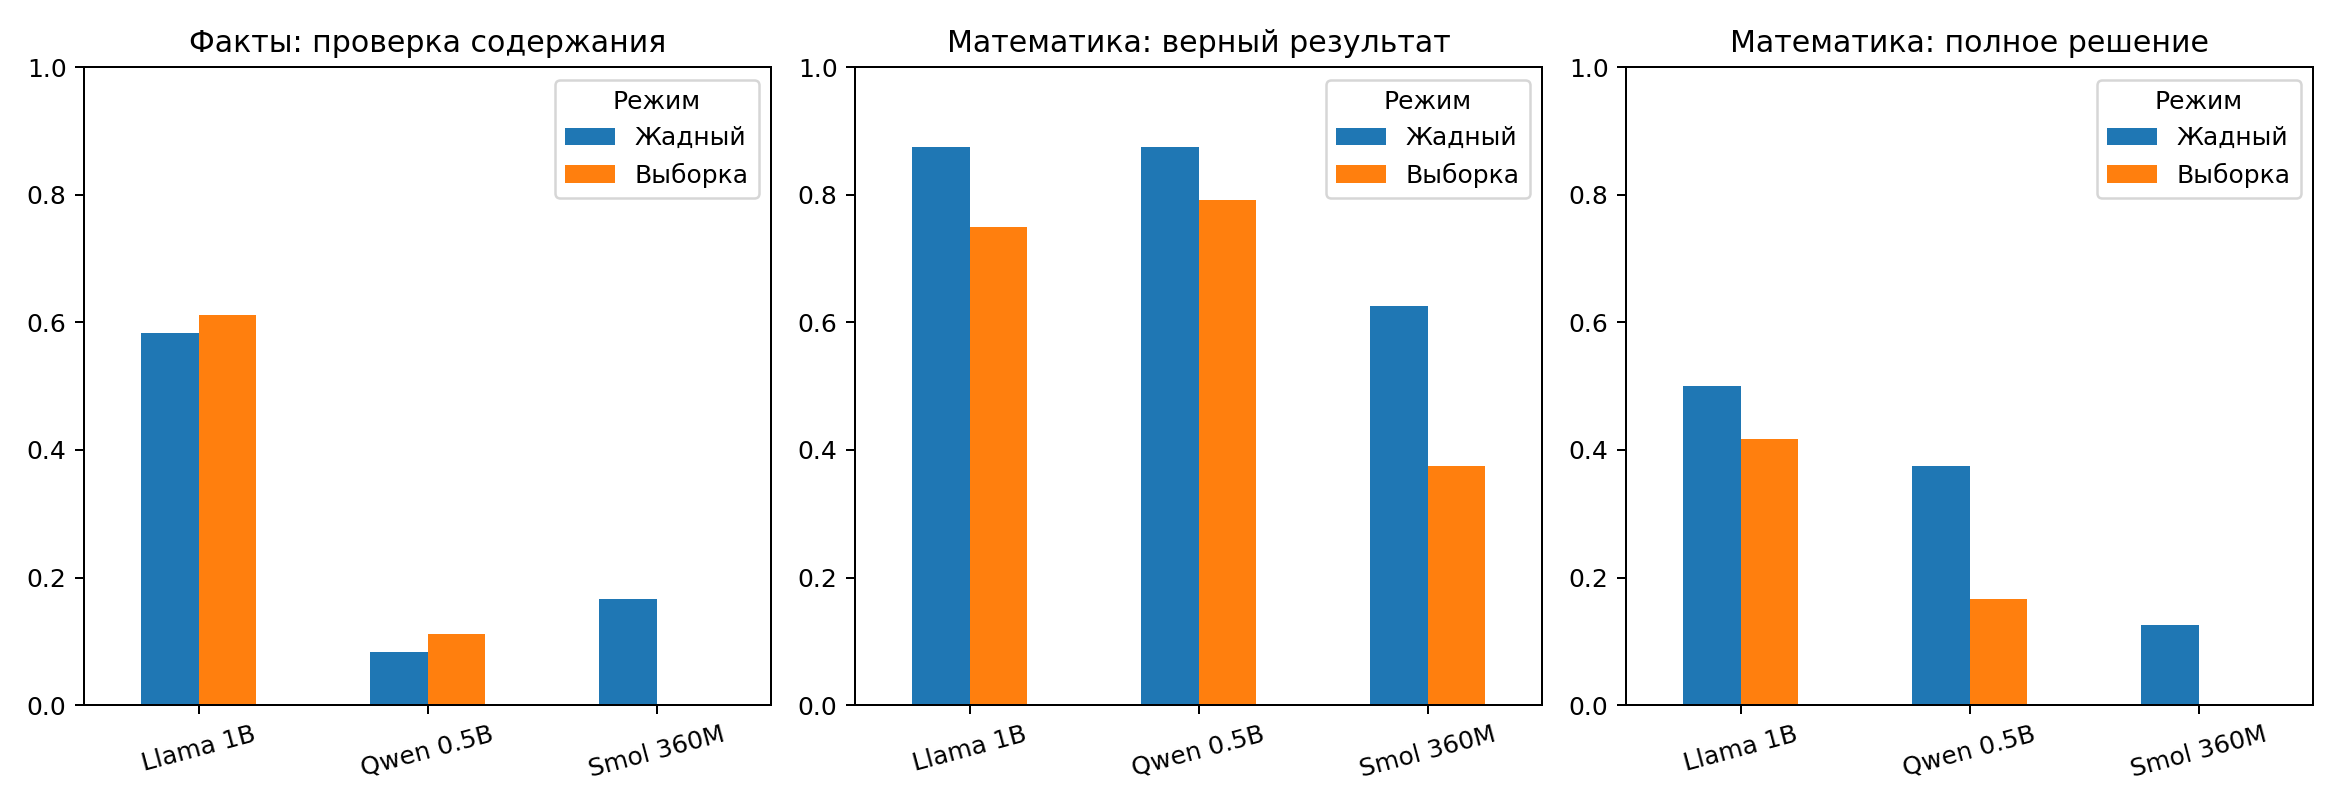

In [7]:
display(Image(filename=str(RUN / "audited_accuracy.png"), width=1100))

## Задержка, скорость и перплексия

Среда: CPU, 4 потока, F16. Низкая PPL не доказывает правильность. Референсная PPL считает все тексты одной Qwen и имеет стилевое смещение.

,Модель,Режим,"Медианное время первого токена, мс","Медианная задержка, мс","P95 задержки, мс","Медианная скорость, токен/с",Взвешенная референсная PPL,Доля обрывов
0,ai/llama3.2:1B-F16,Жадный,1518.140504,4348.539056,13315.385892,13.355456,7.825952,0.100000
1,ai/llama3.2:1B-F16,Выборка,1508.198844,3879.120307,13398.872360,11.683306,9.542279,0.033333
2,ai/qwen2.5:0.5B-F16,Жадный,580.314135,1149.695073,4959.125027,32.187314,11.886951,0.100000
3,ai/qwen2.5:0.5B-F16,Выборка,586.288036,1482.476224,3201.049503,22.574194,29.240947,0.000000
4,ai/smollm2:360m-f16,Жадный,537.462671,1931.151137,4613.699850,41.845757,7.097508,0.350000
5,ai/smollm2:360m-f16,Выборка,545.814226,1886.641415,5054.794893,35.740606,15.289889,0.133333


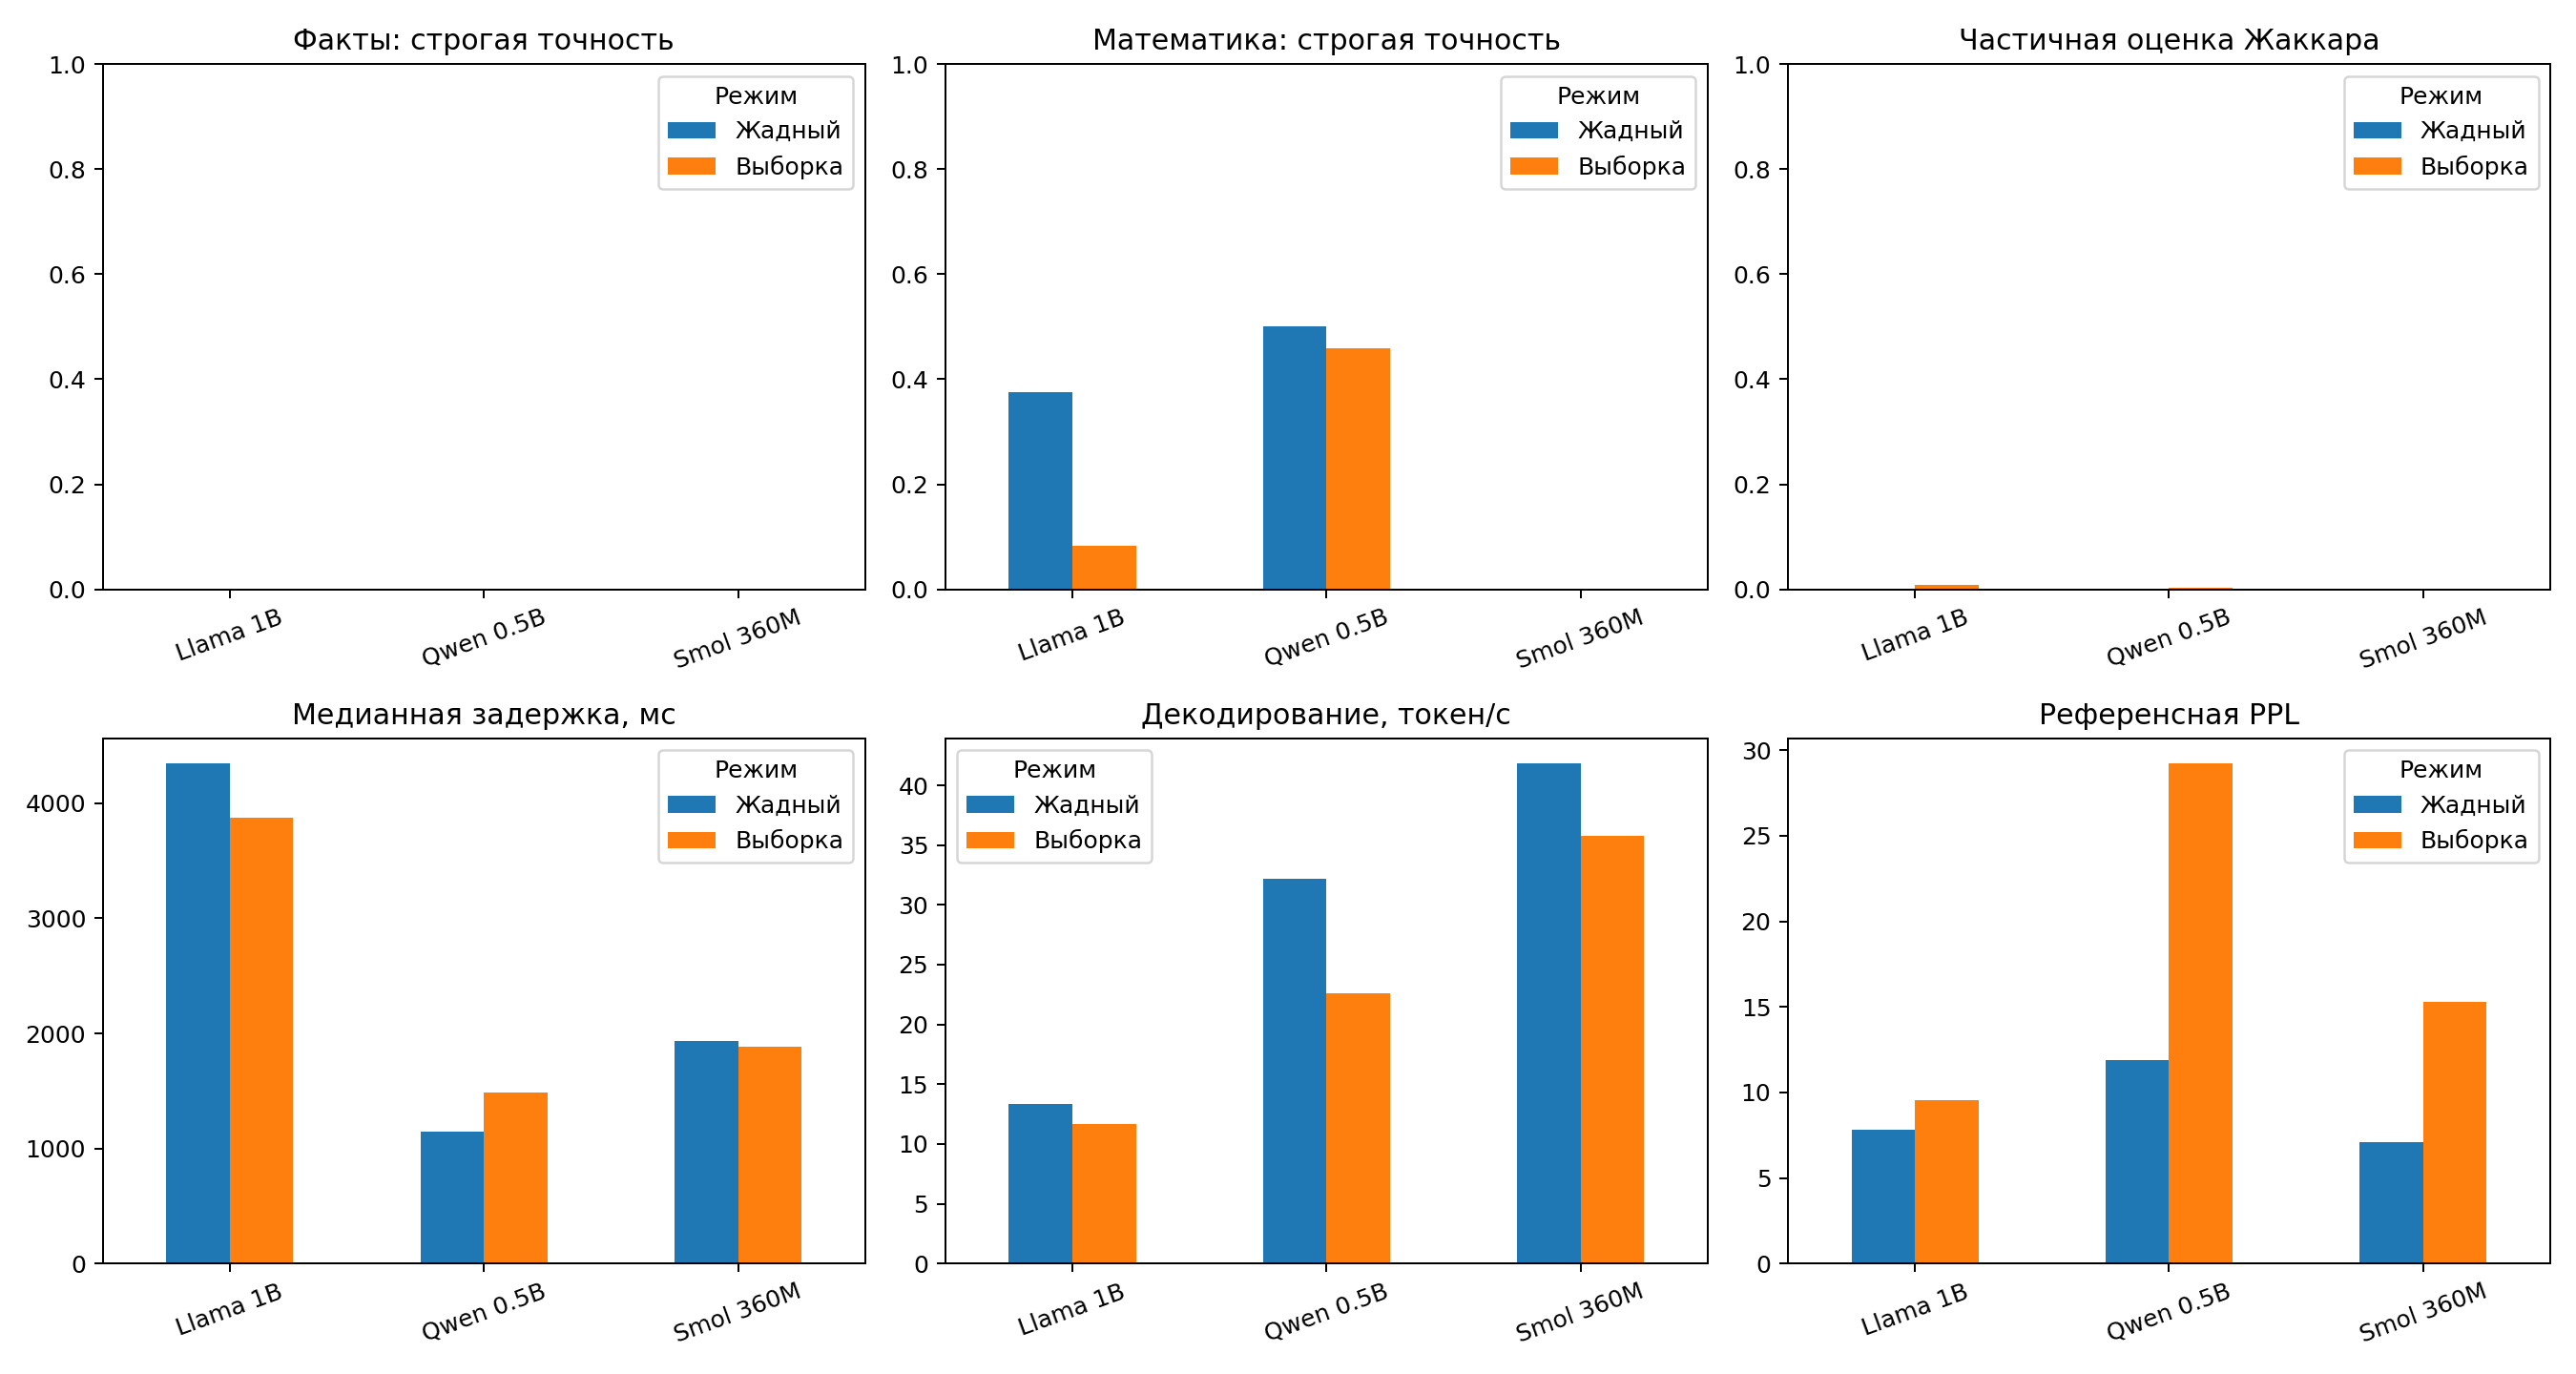

In [8]:
show_ru(aggregate[["model", "mode", "ttft_median_ms", "latency_median_ms", "latency_p95_ms", "decode_tps_median", "reference_ppl_token_weighted", "truncation_rate"]].to_dict("records"))
display(Image(filename=str(RUN / "comparison.png"), width=1100))

In [9]:
resources = json.loads((RUN / "resources.json").read_text(encoding="utf-8"))
show_ru([{
    "model": r["model"], "weights_GiB": r["weight_bytes"] / 2**30,
    "peak_RSS_GiB": r["sampled_peak_rss_bytes"] / 2**30,
    "native_PPL": r["corpus_native"]["ppl"],
    "native_bits_per_byte": r["corpus_native"]["bits_per_byte"]
} for r in resources])

,Модель,"Веса, ГиБ","Пиковая RSS, ГиБ",Собственная PPL,"Собственная оценка, бит/байт"
0,ai/qwen2.5:0.5B-F16,0.925881,1.497631,11.046076,1.355381
1,ai/smollm2:360m-f16,0.675725,0.962727,14.172937,1.751031
2,ai/llama3.2:1B-F16,2.309303,2.839905,8.066218,1.151212


## Неопределённость и парные сравнения

Единица перевыборки — вопрос; его повторы остаются вместе. Интервалы Уилсона используют первый повтор с n=12/8. Бутстреп разведочный.

In [10]:
show_ru(json.loads((RUN / "content_comparisons.json").read_text(encoding="utf-8")))
show_ru(json.loads((RUN / "content_decoding_comparisons.json").read_text(encoding="utf-8")))

,Режим,Модель A,Модель B,Разность A−B / выборка−жадный,Групповой бутстреп: ДИ 95%,Метрика,Вопросов
0,Жадный,ai/llama3.2:1B-F16,ai/qwen2.5:0.5B-F16,0.300000,"[0.05, 0.55]",Правильность содержания,20
1,Жадный,ai/llama3.2:1B-F16,ai/smollm2:360m-f16,0.350000,"[0.05, 0.6]",Правильность содержания,20
2,Жадный,ai/qwen2.5:0.5B-F16,ai/smollm2:360m-f16,0.050000,"[-0.2, 0.3]",Правильность содержания,20
3,Выборка,ai/llama3.2:1B-F16,ai/qwen2.5:0.5B-F16,0.283333,"[0.05, 0.5]",Правильность содержания,20
4,Выборка,ai/llama3.2:1B-F16,ai/smollm2:360m-f16,0.516667,"[0.26666666666666666, 0.7333333333333333]",Правильность содержания,20
5,Выборка,ai/qwen2.5:0.5B-F16,ai/smollm2:360m-f16,0.233333,"[0.1, 0.38333333333333336]",Правильность содержания,20


,Модель,Разность A−B / выборка−жадный,Групповой бутстреп: ДИ 95%,Вопросов
0,ai/llama3.2:1B-F16,-0.033333,"[-0.18333333333333335, 0.1]",20
1,ai/qwen2.5:0.5B-F16,-0.016667,"[-0.10000000000000002, 0.06666666666666667]",20
2,ai/smollm2:360m-f16,-0.200000,"[-0.3666666666666667, -0.05]",20


## Проверка математических решений

Верный результат ≠ верные шаги ≠ полное решение. Проверка одна, выполнена ИИ-ассистентом без независимого оценщика-человека. Решения связаны с хешами текстов.

In [11]:
review = pd.read_csv(RUN / "manual_review.csv")
assert len(review) == 144
show_ru(review[["model", "mode", "id", "repetition", "content_correct", "steps_valid", "solution_complete", "note"]].head(16).to_dict("records"))

,Модель,Режим,Задание,Повтор,Содержание верно,Шаги верны,Решение полное,Пояснение проверки
0,ai/qwen2.5:0.5B-F16,Выборка,15,1,1,0,0,"Числовой результат верен, но запрошенные промежуточные вычисления отсутствуют."
1,ai/qwen2.5:0.5B-F16,Жадный,15,1,1,0,0,"Числовой результат верен, но запрошенные промежуточные вычисления отсутствуют."
2,ai/qwen2.5:0.5B-F16,Жадный,16,0,1,0,0,70 — правильный результат; одно деление не заменяет проверку умножением или промежуточный шаг.
3,ai/qwen2.5:0.5B-F16,Выборка,19,1,0,0,0,Результат 120 или 50 неверен; правильно (20)*(3)=60.
4,ai/qwen2.5:0.5B-F16,Жадный,13,0,1,0,0,"Числовой результат верен, но запрошенные промежуточные вычисления отсутствуют."
5,ai/qwen2.5:0.5B-F16,Выборка,14,2,1,0,0,"Числовой результат верен, но запрошенные промежуточные вычисления отсутствуют."
6,ai/qwen2.5:0.5B-F16,Жадный,19,1,0,0,0,Результат 120 или 50 неверен; правильно (20)*(3)=60.
7,ai/qwen2.5:0.5B-F16,Выборка,13,1,1,0,0,"Числовой результат верен, но запрошенные промежуточные вычисления отсутствуют."
8,ai/qwen2.5:0.5B-F16,Жадный,13,2,1,0,0,"Числовой результат верен, но запрошенные промежуточные вычисления отсутствуют."
9,ai/qwen2.5:0.5B-F16,Выборка,20,1,1,1,1,Цепочка 7²+5²=49+25=74 верна и достаточна; строгий извлекатель не принимает выражение вместо отд...


## Обсуждение и ограничения

In [12]:
from IPython.display import Markdown
display(Markdown((RUN / "discussion.md").read_text(encoding="utf-8")))

# Обсуждение и выводы по измерениям

## Правильность и условная рекомендация

На выбранном наборе **Llama-3.2-1B в жадном режиме** показывает лучшую общую
правильность содержания: **70,0%** против 40,0% у Qwen и 35,0% у SmolLM2.
Преимущество прежде всего фактологическое: 58,3% у Llama, 8,3% у Qwen и 16,7%
у SmolLM2. В истории жадная Llama правильно отвечает на 4 из 6 вопросов, в
румынском языке — на 3 из 6. Даже этого недостаточно для образовательного
использования без проверки.

По числовому математическому результату **жадные Llama и Qwen равны: 87,5%**,
то есть 7/8 вопросов с тем же результатом в трёх повторах. Единственного победителя
здесь нет. Полнота отличается: у Llama 50,0% полных решений, у Qwen 37,5%,
у SmolLM2 12,5%. Точность 87,5% не означает, что столько же доказательств верны
и полны. Для 7/8 интервал Уилсона по первому повтору составляет примерно
[52,9%; 97,8%], что подчёркивает высокую неопределённость.

Строгая фактологическая оценка во всех конфигурациях равна 0%. Это не доказывает
отсутствия знаний: многие правильные ответы не имеют маркера или не совпадают
с конечным списком допустимых форм. Например, Llama называет Кузу без маркера,
а форма «Ștefan III de Moldavia» при проверке распознаётся как Штефан Великий.
Разделение формата и содержания существенно меняет интерпретацию автоматики.

В разведочном сравнении жадных режимов разность Llama–Qwen равна +30 п.п.
с бутстреп-интервалом [5; 55] п.п.; Llama–SmolLM2 — +35 п.п. с [5; 60] п.п.
Интервал Qwen–SmolLM2, [-20; 30] п.п., включает 0. Выводы условны относительно
20 заданий и единственной качественной проверки. Это не подтверждающий тест
с поправкой на множественные сравнения и не универсальное превосходство семейства.

## Политика декодирования

Выборка не повысила среднюю правильность этого эксперимента: Llama снизилась с
70,0% до 66,7%, Qwen — с 40,0% до 38,3%, SmolLM2 — с 35,0% до 15,0%.
Интервалы разности «выборка минус жадный режим» включают 0 у Llama и Qwen;
доказательств устойчивого эффекта для них недостаточно. У SmolLM2 разведочный
интервал равен [-36,7; -5,0] п.п. Наблюдается ухудшение на наборе, но его нельзя
приписать только температуре: одновременно изменены top-p и штраф повторения.

## Скорость и память

**Жадная SmolLM2** имеет наибольшую медианную скорость декодирования — около
**41,85 токена/с**. У жадной Qwen — 32,19, у жадной Llama — 13,36.
Однако медианная задержка меньше у Qwen: около 1,15 с против 1,93 с у SmolLM2.
Ответы имеют разную длину, а SmolLM2 выдаёт больше повторяющегося текста.
Пропускная способность декодирования и время полного ответа не взаимозаменяемы.

SmolLM2 также показывает минимальную наблюдаемую пиковую RSS: около 0,96 ГиБ,
против 1,50 ГиБ у Qwen и 2,84 ГиБ у Llama. При этом доля обрывов жадной SmolLM2
равна 35%, а общая правильность — только 35%. Экономия ресурсов сама по себе
не компенсирует низкую полезность ответов. Qwen быстрее справляется с простой
арифметикой этого набора, но слабо отвечает на фактологические вопросы на румынском.

Если приоритетом является содержание и доступны примерно 3 ГиБ для измеренного
процесса, условный выбор по этим данным — **жадная Llama**. Если нужны только простые
числовые вычисления при меньшей памяти, жадная Qwen достигает той же точности
результата быстрее, однако её шаги необходимо проверять. Ни одну из моделей
нельзя рекомендовать как единственного авторитетного оценщика студенческих работ.

## Перплексия и ошибки рассуждения

Референсная PPL жадной SmolLM2 составляет около 7,10 — меньше, чем 7,83 у Llama,
при общей правильности 35% против 70%. Повторяющийся предсказуемый текст способен
получать низкую PPL; это конкретный пример того, что показатель не удостоверяет
истинность. На общем корпусе собственная PPL равна 8,07 у Llama, 11,05 у Qwen
и 14,17 у SmolLM2, но разные токенизаторы мешают наивному ранжированию. Для
интерпретации нужны биты на байт и условия контекста; сам корпус остаётся коротким.

Проверка выявляет как численно ложные равенства — Qwen утверждает −1=2, — так и
рассуждения с верными отдельными равенствами, но неправильным разложением.
Llama начинает 245+378 с правильного 623, затем прибавляет 200, 78 и 56 и объявляет
финальным ответом 579. Сумма прибавлений равна 334, а не 378. Проверка только
каждого равенства или извлечение первого правильного числа пропустили бы логику ошибки.

## Итоговый вывод

Выполнена фактическая, математическая и ресурсная оценка трёх локально запущенных
моделей с измерением эффективности и перплексии. Основной результат — прослеживаемая
методика, где итоговый ответ, формат, шаги и стоимость являются разными переменными.
Измерения поддерживают условное предпочтение жадной Llama в смешанном сценарии,
не обосновывая перенос вывода на другие наборы, крупные модели или другую аппаратуру.


## Проверка программы

Тесты подтверждают работу оценщика и обработки данных, а не качество языковых моделей.

In [13]:
import xml.etree.ElementTree as ET
suite = ET.parse(ROOT / "reports/tests.xml").find("testsuite")
assert int(suite.attrib["failures"]) == 0 and int(suite.attrib["errors"]) == 0
print("Пройдено программных тестов:", suite.attrib["tests"])
assert (ROOT / "reports/raport.pdf").exists()
print("Русский отчёт PDF/Word и приложения сохранены в проекте.")

Пройдено программных тестов: 29
Русский отчёт PDF/Word и приложения сохранены в проекте.
